## Oppgave 3a)

0 -0.030259166666666667
1 -0.012164999999999999
2 -0.013158333333333334
3 -0.013164166666666664
4 -0.0130125
5 -0.01258083333333333
6 -0.012984166666666665
7 -0.012260000000000002
8 -0.013314999999999999
9 -0.013663333333333333


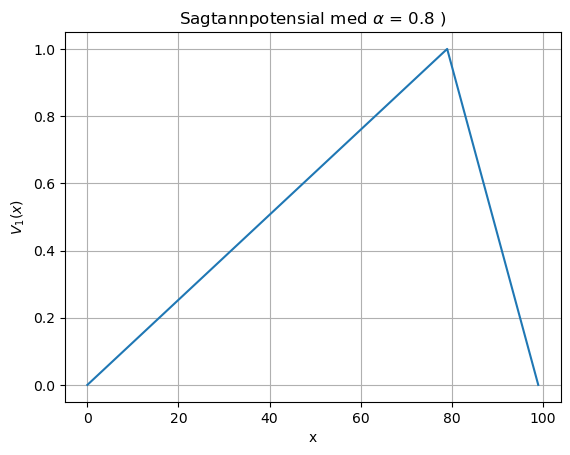

In [41]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 0.8         # plassering av "peak" til sagtann
T_p = 500
h = 1
N_x = 100
P = 2 * N_x         # Lengde på system, to sagtanner
N_p = 12 * N_x      # Antall partikler
Beta_k = 1000
n_steps = 20 * T_p

np.random.seed(0)   # Velger seed for å kunne reprodusere resultat


def build_V1(alpha, N_x):
    peak = int(alpha * (N_x - 1))
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - 1 - n[right]) / max((N_x - 1 - peak), 1)
    
    return np.concatenate([V, V])


V1 = build_V1(alpha, N_x)
V2 = np.zeros(P)

x = np.repeat(np.arange(P), 6)

J = np.zeros(n_steps)

for i in range(n_steps):

    if ((i // T_p) % 2 == 0):
        V = V2
    else:
        V = V1
        
    V_l = V[(x - 1) % P]
    V_0 = V[x]
    V_r = V[(x + 1) % P]

    p_plus  = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
    p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))

    r = np.random.rand(len(x))
    
    pos = np.zeros_like(x) # tomt array med posisjon 0
    pos[r < p_minus] = -1
    pos[r > 1 - p_plus] = +1

    n_plus  = np.sum(pos == 1) # teller hvor mange partikelr som gikk til høyre
    n_minus = np.sum(pos == -1) # teller hvor mange partikelr som gikk til venstre
    J[i] = (n_plus - n_minus) / N_p  # current J[i]

    x = (x + pos) % P  # randbet, x0 -> x199

J_avg = np.zeros(10)

for n in range(10):
    cycle_length = 2 * T_p  # 500 steg i V2 og 500 steg i V1
    start = n * cycle_length
    end = (n + 1) * cycle_length
    J_avg[n] = np.mean(J[start:end])
    print(n, J_avg[n])


# Plot to sagtanner (hele systemet, lengde P = 2*N_x)
plt.figure()
plt.plot(np.arange(N_x), V1[:N_x])
plt.xlabel("x")
plt.ylabel("$V_1(x)$")
plt.title(r"Sagtannpotensial med $\alpha$ = 0.8 )")
plt.grid(True)
plt.show()

#### Kommentar oppgave 3a)

##### For $\alpha$ = 0.8
Avhengig av hvilken "seed" som brukes vil koden skrive ut ulike verdier for de 10 ulike syklusene. For å få reproduserbare resultater ble seed i denne koden satt til 0, og resultatene ble som følger;


| Cycle    | $J_{avg}$ for $\alpha$ = 0.8|         
|:---------|:---------------------------:|
|     1    |  -0.0302592  | 
|     2    | -0.0121650   | 
|     3    |  -0.0131583   | 
|     4    |  -0.0131642   | 
| 5        |  -0.0130125   |  
|  6       |  -0.0125808   |  
|  7       |  -0.0129842   |  
|  8       |  -0.0122600   | 
|  9       |  -0.0133150   |
|  10       |  -0.0136633  |

Siden $\alpha$ > 0.5 betyr det at toppen av sagtannen er forskjøvet mot høyre. Som obervert i tabellen og fra utskriften av koden er all strømningen $J_{avg}$ negativ. I første periode $T_p$ er potensialet helt flatt og partiklene sprer seg tilfeldig. Etter endt periode skrur sagtannpotenialet seg på. Hvordan dette sagtannpotensialet vil se ut er fremstilt i plottet ovenfor. Det viser en topp i $\alpha$ = 0.8, en slak bakke som heller mot venstre og en bratt bakke som heller ned mot høyre. Når dette potensialet er påslått vil partiklener ønske å bevege seg "nedover", altså mot et lavere potensial. Ettersom $\alpha$ er forskjøvet mot høyre vil dermed flere partikler ende opp med å gli ned mot venstre. Det er dette som gir negativ strømning. Den fysiske betydningen av dette er at flere partikler i snitt vil gå ett steg mot venstre over tid.

Som observert i tabellen ovenfor er det en stor økning i $J_{avg}$ fra første til andre syklus.  

In [33]:
J0 = J_avg[0]
J1 = J_avg[1]

change = (J1 - J0) / np.abs(J0) * 100 # %
print(f"Endringen fra første til andre syklus i prosent er lik {change:.2f}")

Endringen fra første til andre syklus i prosent er lik 59.80


Prosentvis er endringen fra syklus 1 til 2 tilnærmet lik 59.80% slik som regnet ut ovenfor, noe som er en markant økning. I starttilstanden til systemet er partiklene helt jevnt fordelt. Det vil dermed ikke være noen foretrukken retning og vil fysisk ikke ligne en naturlig tilstand. Etter første syklus vil partiklene ikke være jevnt fordelt og systemet får et "minne". Dermed kan partiklene falle mer effektiv og strømmen stabiliserer seg. Verdiene flukturer mellom verdiene -0.0137 og -0.0125, noe som kan indikere at systemet har nådd steady state, altså at den har "glemt" starttilstanden. 


0 0.04049083333333333
1 0.028001666666666668
2 0.03150833333333334
3 0.032335833333333334
4 0.029570833333333338
5 0.028752499999999997
6 0.027349166666666664
7 0.029823333333333334
8 0.02976833333333333
9 0.028669999999999998


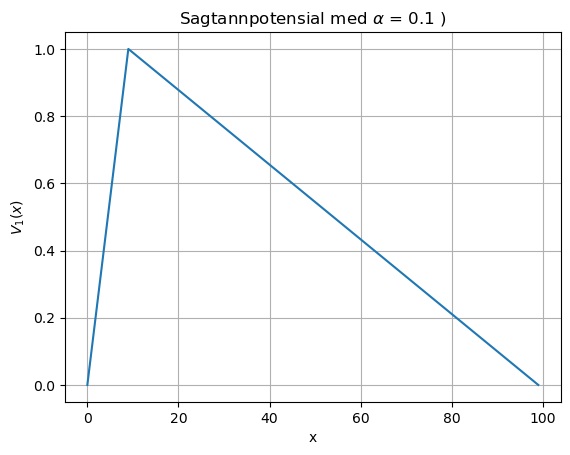

In [43]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 0.1         # plassering av "peak" til sagtann
T_p = 500
h = 1
N_x = 100
P = 2 * N_x         # Lengde på system, to sagtanner
N_p = 12 * N_x      # Antall partikler
Beta_k = 1000
n_steps = 20 * T_p

np.random.seed(0)   # Velger seed for å kunne reprodusere resultat


def build_V1(alpha, N_x):
    peak = int(alpha * (N_x - 1))
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - 1 - n[right]) / max((N_x - 1 - peak), 1)
    
    return np.concatenate([V, V])


V1 = build_V1(alpha, N_x)
V2 = np.zeros(P)

x = np.repeat(np.arange(P), 6)

J = np.zeros(n_steps)

for i in range(n_steps):

    if ((i // T_p) % 2 == 0):
        V = V2
    else:
        V = V1
        
    V_l = V[(x - 1) % P]
    V_0 = V[x]
    V_r = V[(x + 1) % P]

    p_plus  = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
    p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))

    r = np.random.rand(len(x))
    
    pos = np.zeros_like(x) # tomt array med posisjon 0
    pos[r < p_minus] = -1
    pos[r > 1 - p_plus] = +1

    n_plus  = np.sum(pos == 1) # teller hvor mange partikelr som gikk til høyre
    n_minus = np.sum(pos == -1) # teller hvor mange partikelr som gikk til venstre
    J[i] = (n_plus - n_minus) / N_p  # current J[i]

    x = (x + pos) % P  # randbet, x0 -> x199

J_avg2 = np.zeros(10)

for n in range(10):
    cycle_length = 2 * T_p  # 500 steg i V2 og 500 steg i V1
    start = n * cycle_length
    end = (n + 1) * cycle_length
    J_avg2[n] = np.mean(J[start:end])
    print(n, J_avg2[n])


# Plot to sagtanner (hele systemet, lengde P = 2*N_x)
plt.figure()
plt.plot(np.arange(N_x), V1[:N_x])
plt.xlabel("x")
plt.ylabel("$V_1(x)$")
plt.title(r"Sagtannpotensial med $\alpha$ = 0.1 )")
plt.grid(True)
plt.show()

##### For $\alpha$ = 0.1

Ved å sette $\alpha$ = 0.1 blir toppen av sagtannpotensialet forskjøvet mot venstre slik som obersvert i plottet ovenfor. Dette vil dermed resultere i positive verdier for strømningen $J_{avg}$;

| Cycle    | $J_{avg}$ for $\alpha$ = 0.1|         
|:---------|:---------------------------:|
|     1    |  0.0404908  | 
|     2    | 0.0280017   | 
|     3    |  0.0315083  | 
|     4    |  0.0323358   | 
| 5        |  0.0295708|  
|  6       |  0.0287525   |  
|  7       |  0.0273492   |  
|  8       |  0.0298233   | 
|  9       |  0.0297683   |
|  10       |  0.0286700  |

I likhet med når $\alpha$ = 0.8 oppleves en assymetrisk forskyvning som resulterer i at strømningen går i en spesifikk retning. For $\alpha$ = 0.1 gir det positiv strømning, altså går  $J_{avg}$ mot høyre. Ettersom toppen av sagtannen er forskjøvet enda mer i forhold til sentrum for $\alpha$ = 0.1 gir dette også høyere verdier når du ser på absoluttverdien til $J_{avg}$ kontra for $\alpha$ = 0.8. Igjen vil det være et flatt potensial i en tidsperiode $T_p$ før potensialet $V_1$ blir påslått og partiklene vil gli nedover mot lavest potensial. I fysisk betydning vil altså $J_{avg}$ i snitt gå mot høyre.

In [44]:
J0 = J_avg2[0]
J1 = J_avg2[1]

change = (J1 - J0) / np.abs(J0) * 100 # %
print(f"Endringen fra første til andre syklus i prosent er lik {change:.2f}")

Endringen fra første til andre syklus i prosent er lik -30.84


For $\alpha$ = 0.1 blir det en negativ prosentmessig endring fra første til andre syklus. Det tilsier alstå at strømmen endres i retning mot null. Etter å ha gått gjennom flere sykluser vil dette systemet i likhet med forrige stabilisere seg rundt emn bestemt verdi. 